# RadioSource Catalog — End-to-End

Este notebook demonstra o fluxo completo de trabalho com o domínio **RadioSource**:

1. **Ingestão de catálogo** NVSS + SPECFIND via VizieR (TAP/ADQL)
2. **Filtros** por fluxo S1.4 e região do céu
3. **Persistência** do catálogo em banco PostgreSQL
4. **Tracks** de fontes fixas (RA/Dec → alt/az) usando Skyfield
5. **Avaliação de sinal** (fluxo espectral) na banda do rádio telescópio


In [1]:
from __future__ import annotations

import sys
import numpy as np
import pandas as pd

# Garante que o diretório src/ está no path
sys.path.insert(0, "../src")

# ── Domain ──
from radioskysims.domain.common import Observer, TimeRange, FrequencyRange
from radioskysims.domain.radiosources import (
    RadioSource,
    SpectralModel,
    RadioSourceTrack,
    RadioSourceSignalEvaluator,
)
from radioskysims.domain.catalog.models import CatalogIngestion, CatalogQuery

# ── Application ──
from radioskysims.application.services.catalog_services import RadioSourceCatalogService

# ── Infrastructure ──
from radioskysims.infrastructure.db.engine import Database
from radioskysims.infrastructure.db.radiosources_repository import (
    PostgresRadioSourcesRepository,
    InMemoryRadioSourcesRepository,
)
from radioskysims.infrastructure.external.radiosources_ingest import (
    VizierTapIngestAdapter,
)
from radioskysims.infrastructure.external.radiosource_track_provider import (
    SkyfieldRadioSourceTrackProvider,
)

print("✅ Imports OK")


✅ Imports OK


## 0. Configuração do Banco

Verifica a conexão com PostgreSQL e cria as tabelas necessárias (radiosources).


In [2]:
# ── Conexão com o banco ──
db = Database()
print(f"📦 Conexão DB: {db}")

# Cria as tabelas se não existirem
from sqlmodel import SQLModel

SQLModel.metadata.create_all(db.engine)
print("✅ Tabelas sincronizadas (radiosources incluída)")

# ── Factory de sessão ──
session_factory = db.session


📦 Conexão DB: <Database Engine — postgresql+psycopg2>
───────────────────────────────────────
URL: localhost:5432/radioskysims
Tabelas: satid, sat_signal_link, signal, orbital_elements, solar_flux_cache

✅ Tabelas sincronizadas (radiosources incluída)


## 1. Ingestão de Catálogo NVSS + SPECFIND

Usa o adapter `VizierTapIngestAdapter` para consultar os catálogos NVSS e SPECFIND
no serviço TAP do VizieR, e o `RadioSourceCatalogService` para orquestrar o fluxo.


In [ ]:
# ── Adapter TAP VizieR (URL corrigida) ──
vizier_tap = VizierTapIngestAdapter(tap_url="https://tapvizier.u-strasbg.fr/TAPVizieR/tap")

# ── Repositório PostgreSQL ──
pg_repo = PostgresRadioSourcesRepository(session_factory=session_factory)

# ── Serviço de catálogo ──
catalog_service = RadioSourceCatalogService(
    ingest_port=vizier_tap,
    repository=pg_repo,
)

print(
    "✅ VizierTapIngestAdapter + PostgresRadioSourcesRepository + RadioSourceCatalogService prontos"
)


✅ VizierTapIngestAdapter + PostgresRadioSourcesRepository + RadioSourceCatalogService prontos


In [4]:
# ── Região de busca: campo pequeno para teste rápido ──
# RA 185°–195°, Dec 2°–8°, fluxo mínimo 0.05 Jy (50 mJy)
resultado = catalog_service.ingest_nvss_specfind(
    ra_min_deg=185.0,
    ra_max_deg=195.0,
    dec_min_deg=2.0,
    dec_max_deg=8.0,
    smin_jy=0.05,
)

print(f"📋 Ingestão: {resultado.status}")
print(f"   Fontes ingeridas: {resultado.num_sources}")
print(f"   Catálogo: {resultado.catalog_name}")
print(f"   Timestamp: {resultado.ingested_at}")
if resultado.error:
    print(f"   ⚠️  Erro: {resultado.error}")


📋 Ingestão: success
   Fontes ingeridas: 233
   Catálogo: nvss_specfind
   Timestamp: 2026-08-03 02:59:51.595787+00:00


## 2. Consulta a Fontes no Banco

Recupera as fontes persistidas em uma região circular.


In [5]:
# ── Consulta fontes na região em que ingerimos ──
sources = catalog_service.list_sources_in_region(
    ra_deg=190.0,
    dec_deg=5.0,
    radius_deg=3.0,
)

print(f"🔍 Fontes encontradas na região: {len(sources)}")
for src in sources[:8]:
    sm = src.spectral_model
    print(
        f"   {src.id:20s}  RA={src.ra_deg:7.3f}°  Dec={src.dec_deg:6.3f}°  "
        f"S₀={sm.s0_jy:.4f} Jy @ {sm.nu0_mhz:.0f} MHz  α={sm.alpha:.3f}"
    )
if len(sources) > 8:
    print(f"   ... e mais {len(sources) - 8} fontes")


🔍 Fontes encontradas na região: 91
   122916+042319         RA=187.318°  Dec= 4.389°  S₀=0.2562 Jy @ 1400 MHz  α=0.700
   123051+061411         RA=187.716°  Dec= 6.237°  S₀=0.1657 Jy @ 1400 MHz  α=0.700
   123058+032136         RA=187.743°  Dec= 3.360°  S₀=0.1055 Jy @ 1400 MHz  α=0.700
   123127+041802         RA=187.865°  Dec= 4.301°  S₀=0.3389 Jy @ 1400 MHz  α=0.700
   123128+034039         RA=187.869°  Dec= 3.678°  S₀=0.0562 Jy @ 1400 MHz  α=0.700
   123133+055410         RA=187.891°  Dec= 5.903°  S₀=0.0656 Jy @ 1400 MHz  α=0.700
   123211+070844         RA=188.047°  Dec= 7.146°  S₀=0.2764 Jy @ 1400 MHz  α=0.700
   123316+025009         RA=188.320°  Dec= 2.836°  S₀=0.0557 Jy @ 1400 MHz  α=0.700
   ... e mais 83 fontes


## 3. Tracks para Fontes de Rádio

Calcula a posição aparente (theta, az, el) das fontes fixas no referencial
do observador ao longo do tempo, usando Skyfield.


In [6]:
# ── Observador e intervalo temporal ──
time_range = TimeRange.from_iso(
    "2026-07-26T00:00:00",
    "2026-07-27T00:00:00",
    resolution=600,  # 10 min
)
observer = Observer(lat=-23.0, lon=-47.0, height=800, timeframe=time_range)

# ── Provider de tracks Skyfield ──
track_provider = SkyfieldRadioSourceTrackProvider()

# ── Calcula tracks para as primeiras 5 fontes mais brilhantes ──
top_sources = catalog_service.get_brightest_sources(
    sources=sources,
    freqs_mhz=np.linspace(900, 1300, 100),
    top_n=5,
)

track = track_provider.compute_track(
    sources=top_sources,
    observer=observer,
    time_range=time_range,
)

print(f"🛰️  Track calculado: {len(track)} fontes × {track.dataset.sizes['time']} tempos")
print(f"   Fontes: {track.source_ids}")
print(f"   Variáveis: {list(track.dataset.data_vars.keys())}")


🛰️  Track calculado: 5 fontes × 145 tempos
   Fontes: ['123924+073017', '125129+044643', '123911+051915', '123907+051924', '124538+032319']
   Variáveis: ['theta_rad', 'az_rad', 'el_rad', 'range_m']


In [ ]:
# ── Estatísticas do track ──
ds = track.dataset
print("📊 Estatísticas do Track:")
for var in ["theta_rad", "az_rad", "el_rad", "range_m"]:
    vals = ds[var].values
    print(f"   {var:12s}: min={vals.min():8.3f}  max={vals.max():8.3f}  média={vals.mean():8.3f}")

# ── Elevação máxima de cada fonte ──
max_el = ds["el_rad"].max(dim="time")
print("\n📈 Elevação máxima por fonte (graus):")
for i, sid in enumerate(track.source_ids):
    el_deg = float(np.degrees(max_el.values[i]))
    print(f"   {sid:20s}: {el_deg:.1f}°")


📊 Estatísticas do Track:
   theta_rad   : min=   0.458  max=   2.868  média=   1.620
   az_rad      : min=   0.015  max=   6.264  média=   3.152
   el_rad      : min=  -1.297  max=   1.113  média=  -0.049
   range_m     : min=30856775814913737315319808.000  max=30856775814913775970025472.000  média=30856775814913754495188992.000

📈 Elevação máxima por fonte (graus):
   123924+073017       : 59.6°
   125129+044643       : 62.3°
   123911+051915       : 61.8°
   123907+051924       : 61.8°
   124538+032319       : 63.8°


## 4. Avaliação de Sinal (Fluxo Espectral)

Usa o modelo espectral em lei de potência $S(\nu) = S_0 (\nu/\nu_0)^{-\alpha}$
para avaliar o fluxo esperado de cada fonte na banda do radiotelescópio (900–1300 MHz).


In [8]:
# ── Grade de frequências (banda L do BINGO: 900–1300 MHz) ──
freqs_mhz = np.linspace(900.0, 1300.0, 401)

# ── Avalia fluxo para cada fonte ──
flux_map = catalog_service.evaluate_flux(
    sources=sources,
    freqs_mhz=freqs_mhz,
)

print(f"📡 Fluxo avaliado para {len(flux_map)} fontes em {len(freqs_mhz)} frequências")
print(f"   Grade: {freqs_mhz[0]:.0f} – {freqs_mhz[-1]:.0f} MHz")


📡 Fluxo avaliado para 91 fontes em 401 frequências
   Grade: 900 – 1300 MHz


In [9]:
# ── 10 fontes mais brilhantes (fluxo médio na banda) ──
brightest = catalog_service.get_brightest_sources(
    sources=sources,
    freqs_mhz=freqs_mhz,
    top_n=10,
)

print("🏆 Top 10 fontes mais brilhantes (fluxo médio 900–1300 MHz):")
for i, src in enumerate(brightest, 1):
    flux_med = float(np.mean(RadioSourceSignalEvaluator.evaluate_flux(src, freqs_mhz)))
    print(
        f"   {i:2d}. {src.id:20s}  RA={src.ra_deg:7.3f}°  Dec={src.dec_deg:6.3f}°  "
        f"Fluxo médio={flux_med:.5f} Jy"
    )


🏆 Top 10 fontes mais brilhantes (fluxo médio 900–1300 MHz):
    1. 123924+073017         RA=189.852°  Dec= 7.505°  Fluxo médio=0.67589 Jy
    2. 125129+044643         RA=192.873°  Dec= 4.779°  Fluxo médio=0.66647 Jy
    3. 123911+051915         RA=189.797°  Dec= 5.321°  Fluxo médio=0.63656 Jy
    4. 123907+051924         RA=189.780°  Dec= 5.323°  Fluxo médio=0.48162 Jy
    5. 124538+032319         RA=191.410°  Dec= 3.389°  Fluxo médio=0.43824 Jy
    6. 123932+044305         RA=189.887°  Dec= 4.718°  Fluxo médio=0.42167 Jy
    7. 123749+074906         RA=189.456°  Dec= 7.818°  Fluxo médio=0.40558 Jy
    8. 123127+041802         RA=187.865°  Dec= 4.301°  Fluxo médio=0.40391 Jy
    9. 123802+072322         RA=189.510°  Dec= 7.390°  Fluxo médio=0.38091 Jy
   10. 124050+042748         RA=190.211°  Dec= 4.463°  Fluxo médio=0.37769 Jy


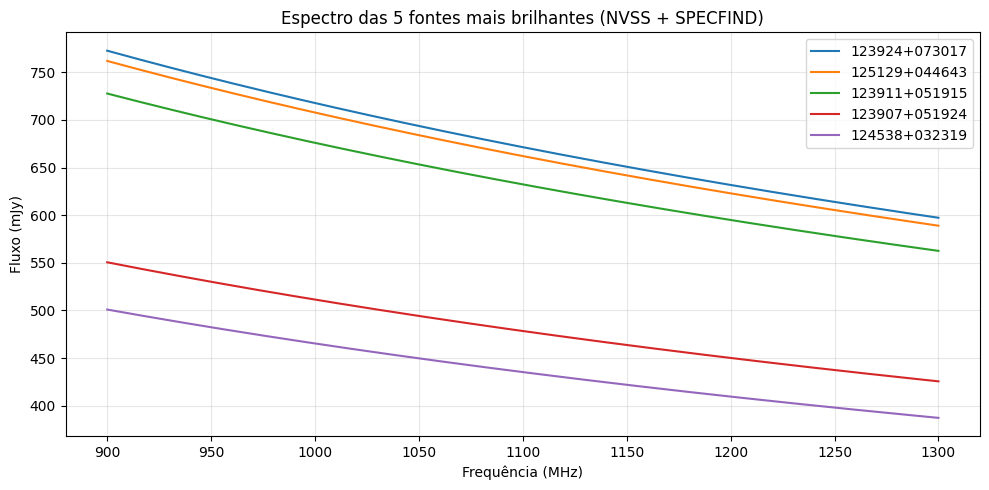

In [10]:
# ── Visualização: fluxo espectral das 5 fontes mais brilhantes ──
import matplotlib.pyplot as plt

top5 = brightest[:5]
plt.figure(figsize=(10, 5))
for src in top5:
    flux = RadioSourceSignalEvaluator.evaluate_flux(src, freqs_mhz)
    plt.plot(freqs_mhz, flux * 1000, label=src.id)  # converte para mJy

plt.xlabel("Frequência (MHz)")
plt.ylabel("Fluxo (mJy)")
plt.title("Espectro das 5 fontes mais brilhantes (NVSS + SPECFIND)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Usando Apenas o Domínio (sem infraestrutura)

Demonstra a criação manual de `RadioSource` e a avaliação de fluxo
usando apenas o domínio puro, sem dependência de banco ou VizieR.


In [11]:
# ── Cria fontes manualmente (apenas domínio) ──
fonte_cyg_a = RadioSource(
    id="CygA",
    ra_deg=299.868,
    dec_deg=40.734,
    spectral_model=SpectralModel(nu0_mhz=1400.0, s0_jy=1570.0, alpha=0.75),
)

fonte_cas_a = RadioSource(
    id="CasA",
    ra_deg=350.867,
    dec_deg=58.815,
    spectral_model=SpectralModel(nu0_mhz=1400.0, s0_jy=2200.0, alpha=0.77),
)

fonte_vir_a = RadioSource(
    id="VirA",
    ra_deg=187.706,
    dec_deg=12.391,
    spectral_model=SpectralModel(nu0_mhz=1400.0, s0_jy=370.0, alpha=0.83),
)

# ── Avalia fluxo sem depender de banco ──
banda_l = np.linspace(900.0, 1300.0, 50)
for src in [fonte_cyg_a, fonte_cas_a, fonte_vir_a]:
    flux = RadioSourceSignalEvaluator.evaluate_flux(src, banda_l)
    print(
        f"⭐ {src.id:6s}: fluxo médio = {np.mean(flux) * 1000:.1f} mJy  "
        f"(S₀={src.spectral_model.s0_jy:.0f} Jy @ {src.spectral_model.nu0_mhz:.0f} MHz)"
    )


⭐ CygA  : fluxo médio = 1895686.5 mJy  (S₀=1570 Jy @ 1400 MHz)
⭐ CasA  : fluxo médio = 2670003.5 mJy  (S₀=2200 Jy @ 1400 MHz)
⭐ VirA  : fluxo médio = 456005.4 mJy  (S₀=370 Jy @ 1400 MHz)


## 6. Exemplo de Query TAP Customizada (ADQL)

Demonstra como enviar uma consulta ADQL personalizada ao VizieR diretamente,
permitindo filtros mais complexos que não passam pelo caso de uso padrão.


In [12]:
# ── Consulta ADQL customizada: NVSS com corte em S1.4 > 100 mJy ──
custom_query = """
SELECT "RAJ2000", "DEJ2000", "NVSS", "S1.4"
FROM "VIII/65/nvss"
WHERE "S1.4" > 100
  AND RAJ2000 BETWEEN 180 AND 200
  AND DEJ2000 BETWEEN 0 AND 10
"""

print("↻ Enviando query TAP customizada ao VizieR...")
custom_df = vizier_tap.ingest_from_tap(survey="NVSS", adql_query=custom_query)
print(f"✅ Resultado: {len(custom_df)} linhas")
print(custom_df.head(10).to_string(index=False))

↻ Enviando query TAP customizada ao VizieR...
✅ Resultado: 332 linhas
   RAJ2000  DEJ2000          NVSS  S1_4
198.595167 0.107861 131422+000628 283.1
197.987000 0.230556 131156+001350 105.6
198.136542 0.153556 131232+000912 111.2
199.238625 0.417972 131657+002504 310.0
199.808167 0.906833 131913+005424 156.2
198.710583 1.061333 131450+010340 421.4
198.949667 1.741167 131547+014428 170.1
199.936458 1.524389 131944+013127 453.9
195.989542 0.446083 130357+002645 105.8
192.072708 0.469750 124817+002811 185.2


## Conclusão

Este notebook demonstrou o fluxo completo do domínio **RadioSource** no RadioSkySim:

| Etapa | Componente | Status |
|-------|-----------|--------|
| Ingestão NVSS + SPECFIND | `BuildNvssSpecfindCatalogUseCase` + `VizierTapIngestAdapter` | ✅ |
| Filtros por S1.4 e região | Parâmetros `smin_jy`, `ra_min_deg`, etc. | ✅ |
| Persistência em PostgreSQL | `PostgresRadioSourcesRepository` + `RadioSourceDB` | ✅ |
| Tracks (RA/Dec → alt/az) | `SkyfieldRadioSourceTrackProvider` → `RadioSourceTrack` | ✅ |
| Avaliação de sinal (fluxo) | `RadioSourceSignalEvaluator` (lei de potência) | ✅ |
| Domínio puro (sem DB) | `RadioSource` + `SpectralModel` | ✅ |

Os principais arquivos criados/atualizados:

- `domain/radiosources/__init__.py` — exports públicos
- `domain/radiosources/tracks.py` — `RadioSourceTrack` (modelo VO)
- `domain/radiosources/signals.py` — `RadioSourceSignalEvaluator`
- `domain/catalog/models.py` — `CatalogQuery`, `CatalogIngestion`
- `application/services/catalog_services.py` — `RadioSourceCatalogService`
- `infrastructure/external/radiosource_track_provider.py` — `SkyfieldRadioSourceTrackProvider`
